# Task 5: K-Means, Gaussian Mixture and Hierarchical Clustering

**Dataset:** `store_sales_dataset.csv`

We group the orders into clusters using `Quantity` and `Unit_Price` with three
unsupervised algorithms:

1. **K-Means**
2. **Gaussian Mixture Model** (mixture of Gaussians)
3. **Hierarchical (Agglomerative) Clustering**

`Category` is **not** used for training. It is only used afterwards to check how
well the clusters match the real categories.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

%matplotlib inline

## 2. Load data

In [2]:
df = pd.read_csv("store_sales_dataset.csv")
print(f"Dataset size: {len(df)} rows")
df.head()

Dataset size: 500 rows


,Order_ID,Product,Category,City,Quantity,Unit_Price,Total_Sales
0,101,Smartphone,Electronics,Hyderabad,5,12450,62250
1,102,USB Cable,Accessories,Delhi,2,4550,9100
2,103,Television,Electronics,Mumbai,38,11800,448400
3,104,Power Bank,Accessories,Hyderabad,12,6750,81000
4,105,Webcam,Accessories,Bangalore,34,2950,100300


## 3. Prepare and standardize the features

Both features are standardized (mean = 0, std = 1) so they have equal weight.

In [3]:
features = ["Quantity", "Unit_Price"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Features used for clustering: {features}")

Features used for clustering: ['Quantity', 'Unit_Price']


## 4. Choosing the number of clusters (Elbow method + Silhouette score)

In [4]:
k_values = range(2, 9)
inertias = []
silhouettes = []

print(f"  {'k':>3} {'Inertia':>12} {'Silhouette':>12}")
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    print(f"  {k:>3} {km.inertia_:>12.2f} {silhouettes[-1]:>12.4f}")

best_k = list(k_values)[int(np.argmax(silhouettes))]
print(f"\nBest k by silhouette score: {best_k}")

    k      Inertia   Silhouette


    2       626.59       0.3675


    3       351.55       0.4355
    4       281.85       0.4012


    5       224.62       0.3603


    6       179.95       0.3845
    7       150.08       0.3789


    8       129.58       0.3745

Best k by silhouette score: 3


### Graph: Elbow method and Silhouette scores

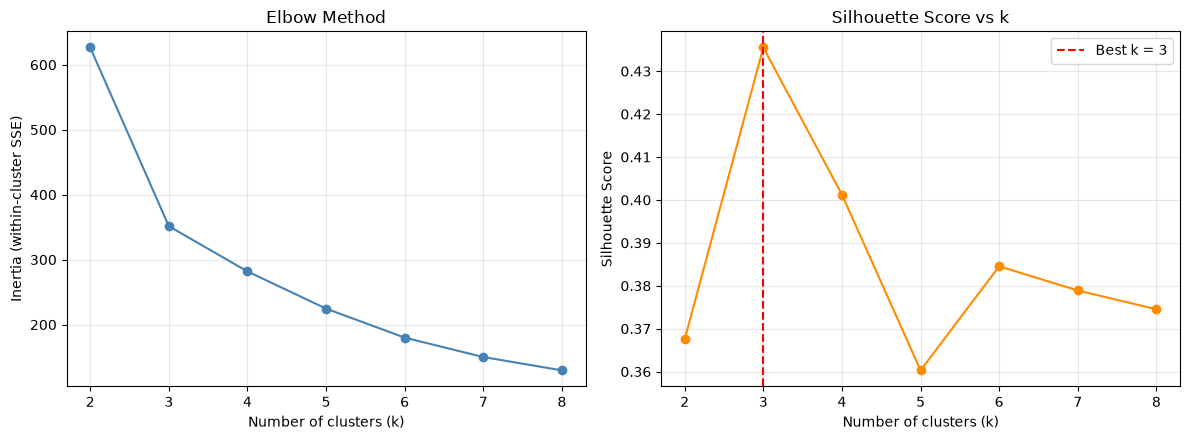

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(k_values), inertias, marker="o", color="steelblue")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow Method")
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(k_values), silhouettes, marker="o", color="darkorange")
axes[1].axvline(best_k, color="red", linestyle="--", label=f"Best k = {best_k}")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score vs k")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. K-Means clustering

In [6]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

centers = scaler.inverse_transform(kmeans.cluster_centers_)
print(f"K-Means (k = {best_k}) cluster centers (original units):")
pd.DataFrame(centers, columns=features).round(2)

K-Means (k = 3) cluster centers (original units):


,Quantity,Unit_Price
0,11.66,9172.56
1,31.35,9214.06
2,21.72,23048.92


### Graph: K-Means clusters

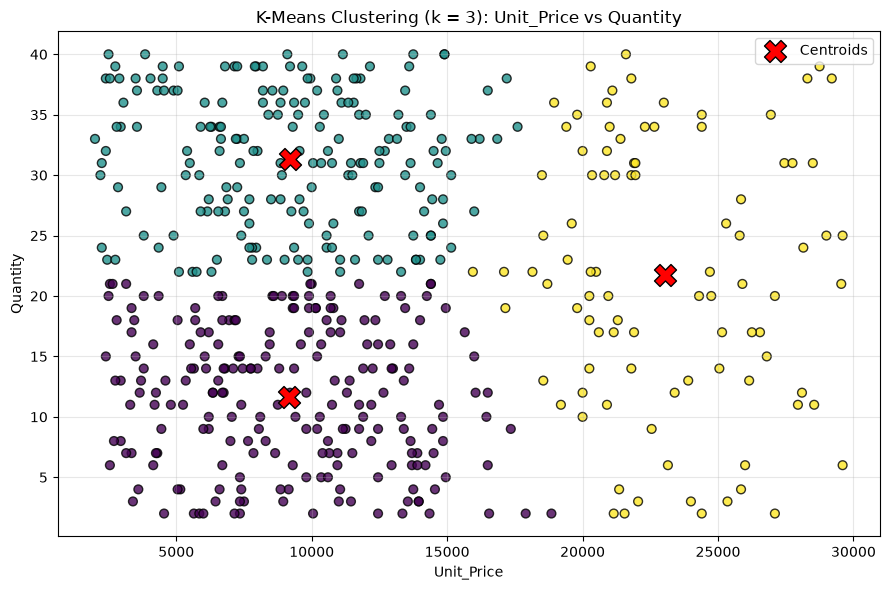

In [7]:
plt.figure(figsize=(9, 6))
plt.scatter(
    df["Unit_Price"],
    df["Quantity"],
    c=kmeans_labels,
    cmap="viridis",
    edgecolor="black",
    s=40,
    alpha=0.8,
)
plt.scatter(
    centers[:, 1],
    centers[:, 0],
    color="red",
    marker="X",
    s=250,
    edgecolor="black",
    label="Centroids",
)
plt.xlabel("Unit_Price")
plt.ylabel("Quantity")
plt.title(f"K-Means Clustering (k = {best_k}): Unit_Price vs Quantity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Gaussian Mixture Model

In [8]:
gmm = GaussianMixture(n_components=best_k, covariance_type="full", random_state=42)
gmm.fit(X_scaled)
gmm_labels = gmm.predict(X_scaled)
gmm_probs = gmm.predict_proba(X_scaled)

print("Mixture weights:")
for i, w in enumerate(gmm.weights_):
    print(f"  Component {i}: {w:.4f}")

gmm_means = scaler.inverse_transform(gmm.means_)
print("\nComponent means (original units):")
print(pd.DataFrame(gmm_means, columns=features).round(2).to_string())

print(f"\nConverged: {gmm.converged_}")
print(f"Log-likelihood (per sample): {gmm.score(X_scaled):.4f}")
print(f"BIC: {gmm.bic(X_scaled):.2f}")
print(f"AIC: {gmm.aic(X_scaled):.2f}")

Mixture weights:
  Component 0: 0.4446
  Component 1: 0.3718
  Component 2: 0.1836

Component means (original units):
   Quantity  Unit_Price
0     12.39     9036.62
1     31.30     9540.81
2     21.50    22903.59

Converged: True
Log-likelihood (per sample): -2.6536
BIC: 2759.27
AIC: 2687.62


### Soft assignments: membership probabilities (first 10 rows)

In [9]:
prob_df = pd.DataFrame(
    np.round(gmm_probs, 4),
    columns=[f"P(Comp {i})" for i in range(best_k)],
)
prob_df.insert(0, "Unit_Price", df["Unit_Price"].values)
prob_df.insert(0, "Quantity", df["Quantity"].values)
prob_df.head(10)

,Quantity,Unit_Price,P(Comp 0),P(Comp 1),P(Comp 2)
0,5,12450,0.9969,0.0001,0.0030
1,2,4550,1.0000,0.0000,0.0000
2,38,11800,0.0005,0.9962,0.0033
3,12,6750,0.9981,0.0019,0.0000
4,34,2950,0.0083,0.9917,0.0000
5,15,26800,0.0001,0.0001,0.9998
6,4,13750,0.9893,0.0001,0.0106
7,18,6950,0.9436,0.0563,0.0000
8,22,5100,0.7171,0.2829,0.0000
9,21,14400,0.4475,0.4848,0.0677


### Graph: Gaussian Mixture clusters

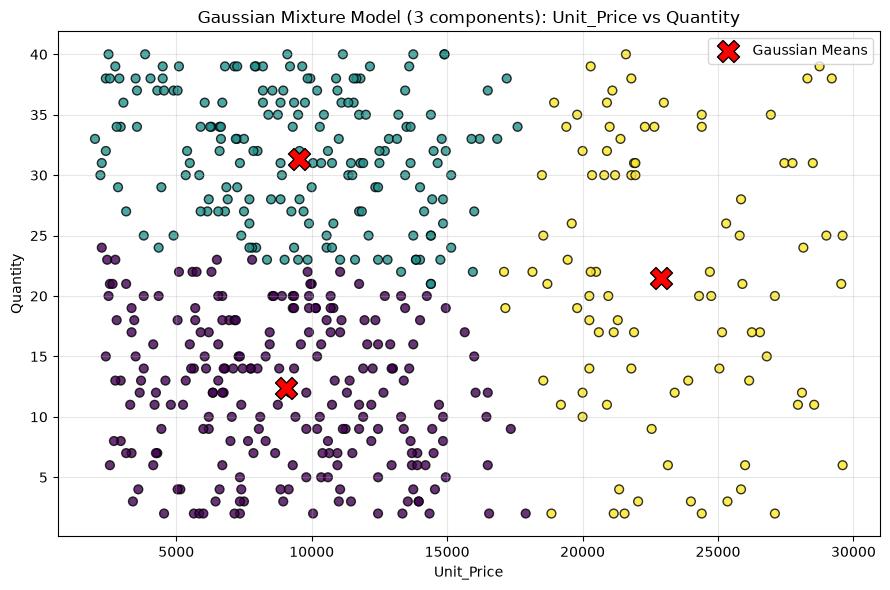

In [10]:
plt.figure(figsize=(9, 6))
plt.scatter(
    df["Unit_Price"],
    df["Quantity"],
    c=gmm_labels,
    cmap="viridis",
    edgecolor="black",
    s=40,
    alpha=0.8,
)
plt.scatter(
    gmm_means[:, 1],
    gmm_means[:, 0],
    color="red",
    marker="X",
    s=250,
    edgecolor="black",
    label="Gaussian Means",
)
plt.xlabel("Unit_Price")
plt.ylabel("Quantity")
plt.title(f"Gaussian Mixture Model ({best_k} components): Unit_Price vs Quantity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Hierarchical (Agglomerative) clustering with Ward linkage

In [11]:
hier = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hier_labels = hier.fit_predict(X_scaled)
print(f"Hierarchical clustering done with k = {best_k}")

Hierarchical clustering done with k = 3


### Graph 1: Dendrogram

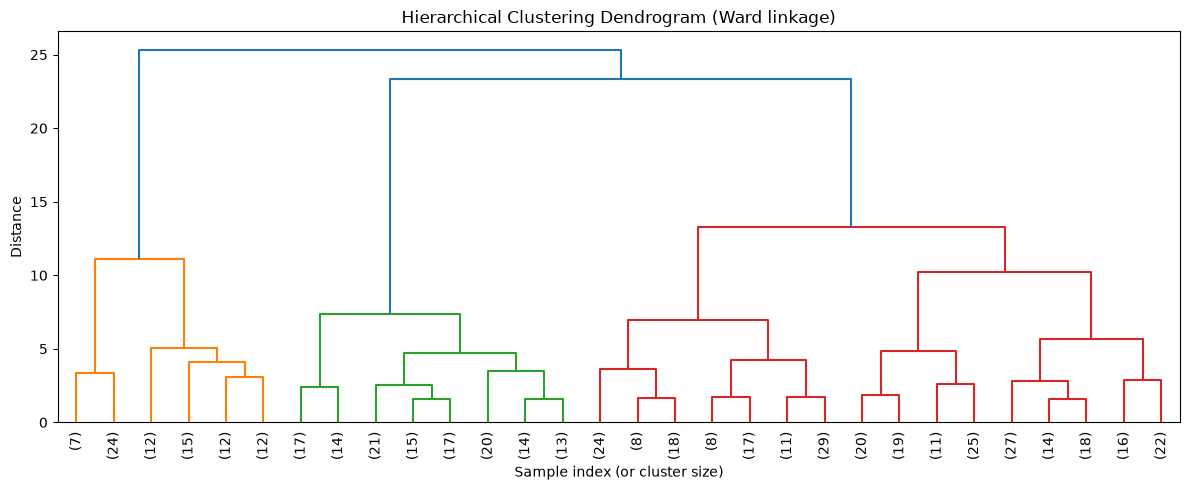

In [12]:
linkage_matrix = linkage(X_scaled, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(linkage_matrix, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.xlabel("Sample index (or cluster size)")
plt.ylabel("Distance")
plt.title("Hierarchical Clustering Dendrogram (Ward linkage)")
plt.tight_layout()
plt.show()

### Graph 2: Hierarchical clusters

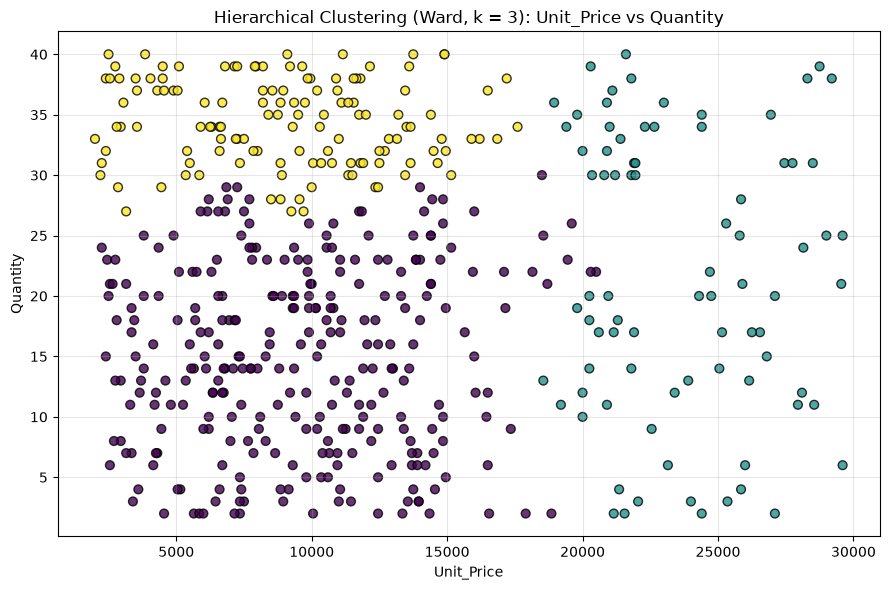

In [13]:
plt.figure(figsize=(9, 6))
plt.scatter(
    df["Unit_Price"],
    df["Quantity"],
    c=hier_labels,
    cmap="viridis",
    edgecolor="black",
    s=40,
    alpha=0.8,
)
plt.xlabel("Unit_Price")
plt.ylabel("Quantity")
plt.title(f"Hierarchical Clustering (Ward, k = {best_k}): Unit_Price vs Quantity")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Evaluation and comparison

- **Silhouette score:** cluster quality (higher is better, max 1)
- **Adjusted Rand Index (ARI):** agreement with the real `Category` (1 = perfect, 0 = random)

In [14]:
results = {
    "K-Means": kmeans_labels,
    "Gaussian Mixture": gmm_labels,
    "Hierarchical": hier_labels,
}

rows = []
for name, labels in results.items():
    rows.append({
        "Algorithm": name,
        "Silhouette": round(silhouette_score(X_scaled, labels), 4),
        "ARI vs Category": round(adjusted_rand_score(df["Category"], labels), 4),
    })
scores_df = pd.DataFrame(rows)
scores_df

,Algorithm,Silhouette,ARI vs Category
0,K-Means,0.4355,0.1016
1,Gaussian Mixture,0.4330,0.1049
2,Hierarchical,0.3873,0.0802


In [15]:
for name, labels in results.items():
    print(f"\n{name} - cluster sizes and Category breakdown:")
    print(pd.crosstab(labels, df["Category"], rownames=["Cluster"]).to_string())


K-Means - cluster sizes and Category breakdown:
Category  Accessories  Electronics
Cluster                           
0                 132           83
1                 118           74
2                   0           93

Gaussian Mixture - cluster sizes and Category breakdown:
Category  Accessories  Electronics
Cluster                           
0                 142           81
1                 108           76
2                   0           93

Hierarchical - cluster sizes and Category breakdown:
Category  Accessories  Electronics
Cluster                           
0                 169          118
1                   0           82
2                  81           50


### Graph: Silhouette and ARI comparison

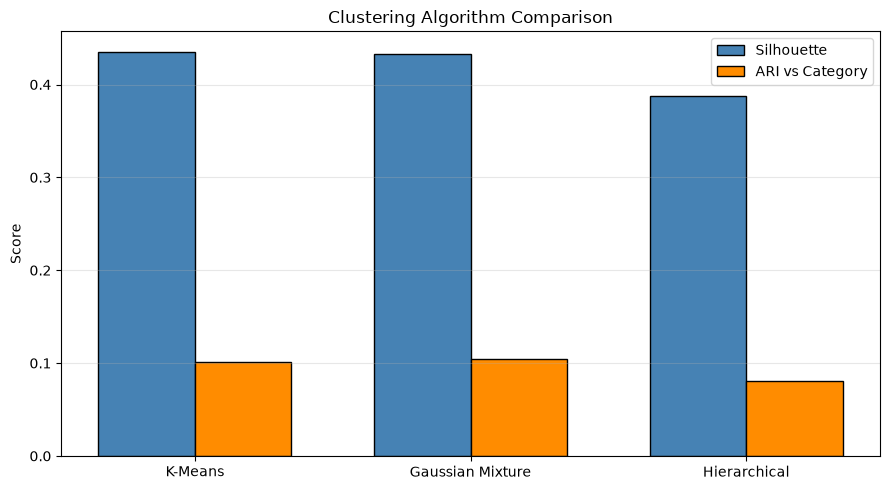

In [16]:
x = np.arange(len(scores_df))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width / 2, scores_df["Silhouette"], width, label="Silhouette",
        color="steelblue", edgecolor="black")
plt.bar(x + width / 2, scores_df["ARI vs Category"], width, label="ARI vs Category",
        color="darkorange", edgecolor="black")
plt.xticks(x, scores_df["Algorithm"])
plt.ylabel("Score")
plt.title("Clustering Algorithm Comparison")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Sample prediction (new data point)

In [17]:
sample = pd.DataFrame({"Quantity": [10], "Unit_Price": [20000]})
sample_scaled = scaler.transform(sample)

print("Quantity=10, Unit_Price=20000")
print(f"  K-Means cluster:          {kmeans.predict(sample_scaled)[0]}")
print(f"  Gaussian Mixture cluster: {gmm.predict(sample_scaled)[0]}")
print(f"  GMM probabilities:        {np.round(gmm.predict_proba(sample_scaled)[0], 4)}")

Quantity=10, Unit_Price=20000
  K-Means cluster:          2
  Gaussian Mixture cluster: 2
  GMM probabilities:        [0.1529 0.0013 0.8458]
